<a href="https://colab.research.google.com/github/mohammadbadi/CrimeAnalytics_Clustering/blob/main/Code%20Sections/5.4.2%20Data%20Reduction%20and%20Projection(E).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **5.4 Data Reduction and Projection - e) EDA**

Generating Box Plot for Numerical Features...


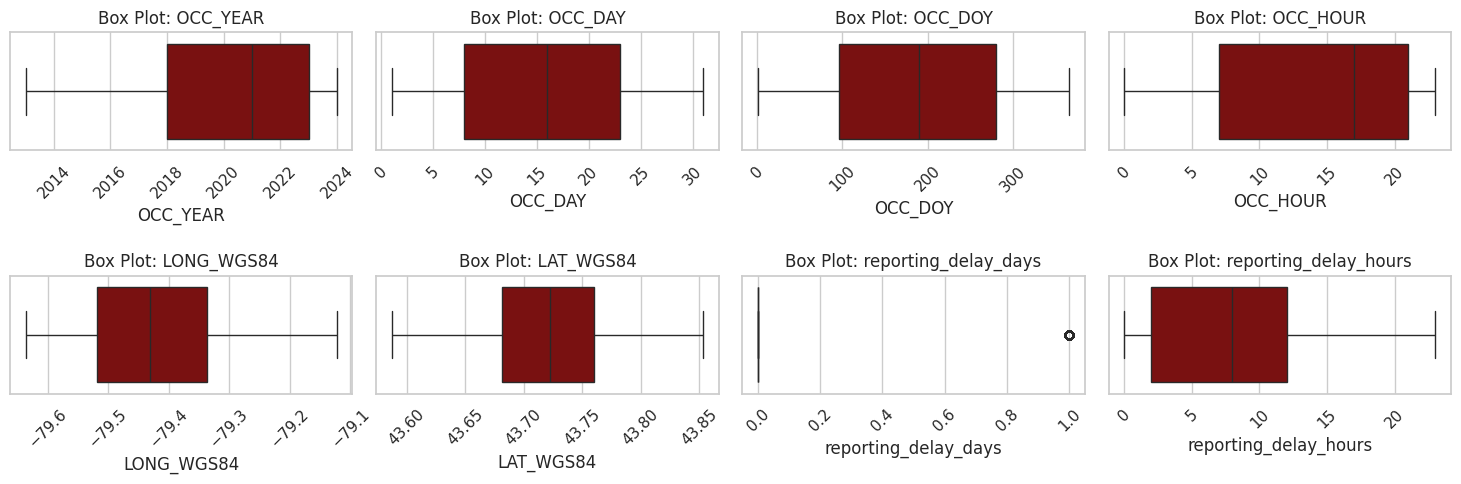

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Generating Line Chart for Missing Values per Column...


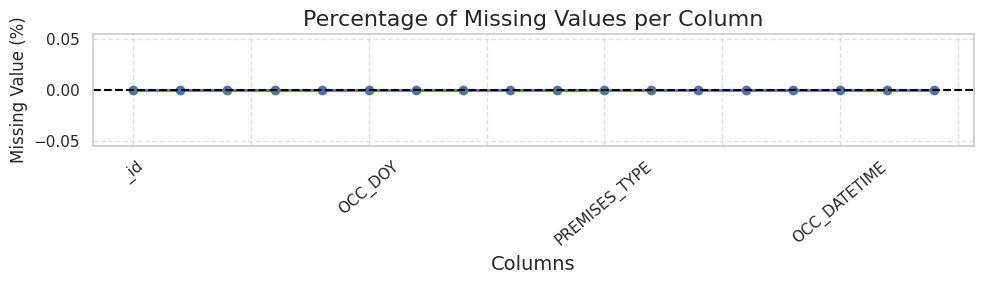

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Generating Bar Plots for Incidents per Year, Month, and Day of the Week...


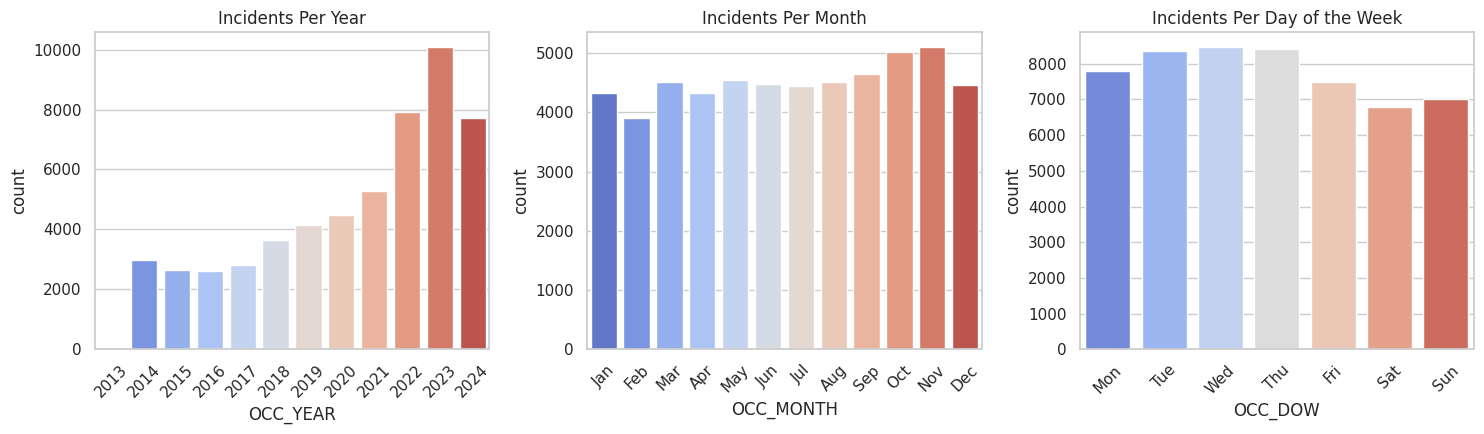

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Generating Distribution Plots for Categorical Features...

===== DIVISION Distribution =====

DIVISION
D23    7021
D32    6552
D31    5351
D22    5341
D42    4586
D43    3228
D33    3137
D53    3093
D41    2989
D12    2847
D55    2433
D13    2151
D14    1640
D11    1621
D51    1266
D52     780
D54     275




<ipython-input-3-30df50e4f7c0>:97: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[idx].set_yticklabels(labels)



===== LOCATION_TYPE Distribution =====

LOCATION_TYPE
Single Home, House (Attach Garage, Cottage, Mobile)                       18882
Parking Lots (Apt., Commercial Or Non-Commercial)                         17965
Streets, Roads, Highways (Bicycle Path, Private Road)                     10848
Other Commercial / Corporate Places (For Profit, Warehouse, Corp. Bldg     1794
Private Property Structure (Pool, Shed, Detached Garage)                   1514
Apartment (Rooming House, Condo)                                           1457
Dealership (Car, Motorcycle, Marine, Trailer, Etc.)                         472
Gas Station (Self, Full, Attached Convenience)                              282
Commercial Dwelling Unit (Hotel, Motel, B & B, Short Term Rental)           218
Open Areas (Lakes, Parks, Rivers)                                           134
Bar / Restaurant                                                            124
Ttc Subway Station                                               

<ipython-input-3-30df50e4f7c0>:97: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[idx].set_yticklabels(labels)



===== PREMISES_TYPE Distribution =====

PREMISES_TYPE
Outside        28949
House          18882
Commercial      3028
Other           1740
Apartment       1457
Transit          180
Educational       75




<ipython-input-3-30df50e4f7c0>:97: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[idx].set_yticklabels(labels)



===== NEIGHBOURHOOD_158 Distribution =====

NEIGHBOURHOOD_158
West Humber-Clairville (1)                3724
York University Heights (27)              1254
Etobicoke City Centre (159)               1118
Milliken (130)                             925
Humber Summit (21)                         893
Oakdale-Beverley Heights (154)             839
Bedford Park-Nortown (39)                  834
Yorkdale-Glen Park (31)                    818
Glenfield-Jane Heights (25)                798
Newtonbrook West (36)                      798
Wexford/Maryvale (119)                     792
Mount Olive-Silverstone-Jamestown (2)      747
Clanton Park (33)                          705
Humbermede (22)                            629
Willowridge-Martingrove-Richview (7)       623
Kingsview Village-The Westway (6)          596
Morningside Heights (144)                  596
Stonegate-Queensway (16)                   591
Bendale-Glen Andrew (156)                  577
Weston (113)                               5

<ipython-input-3-30df50e4f7c0>:97: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[idx].set_yticklabels(labels)


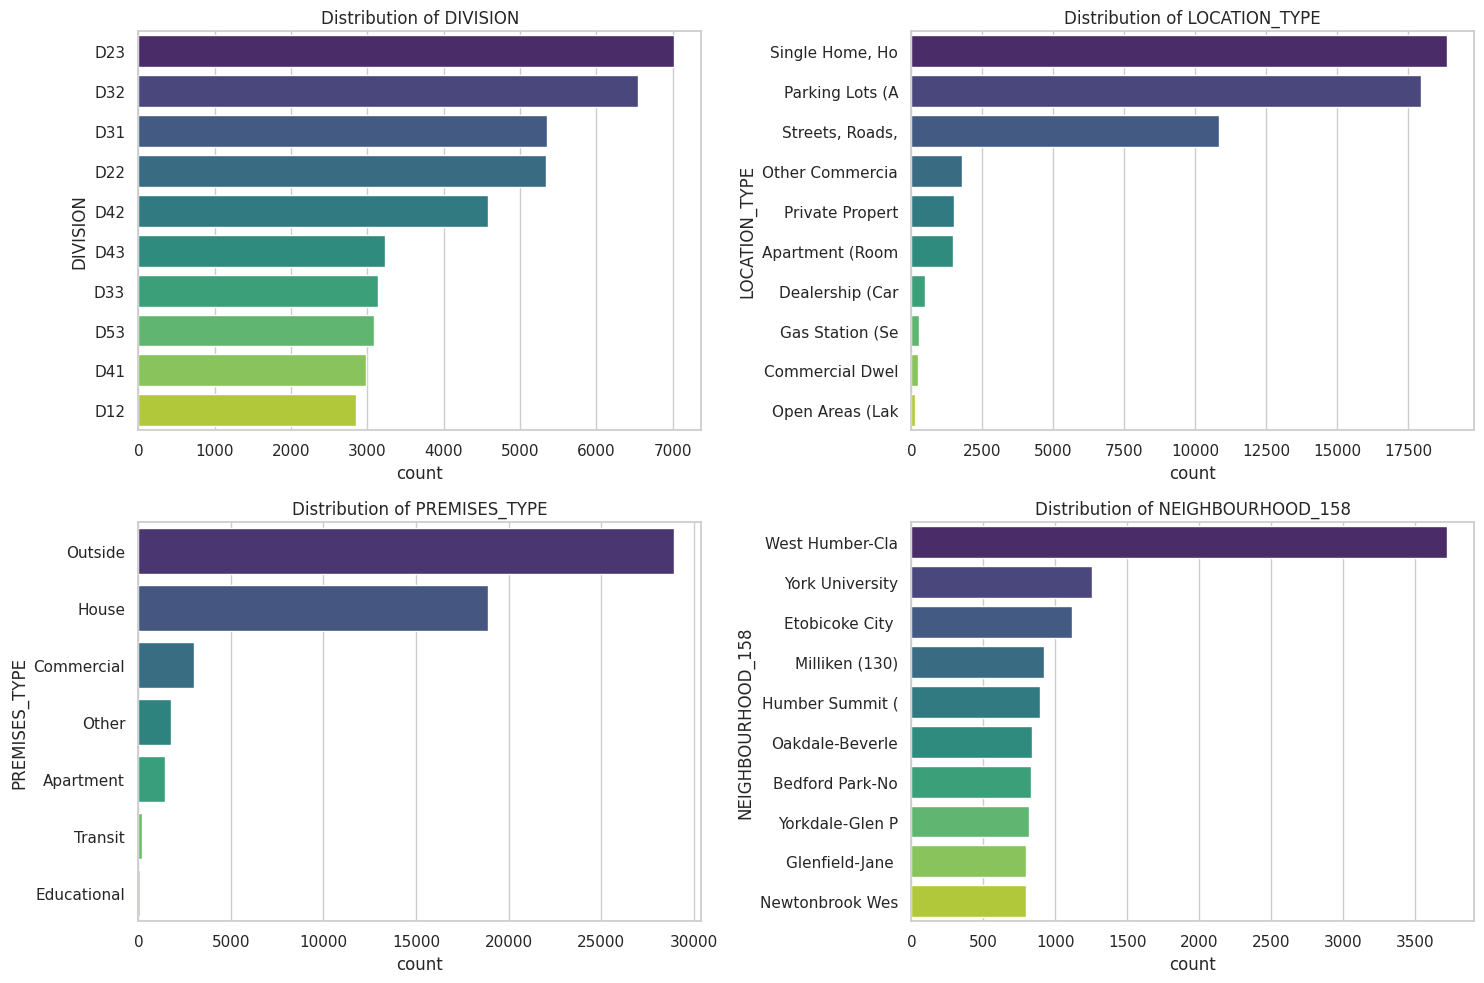

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Generating Colour Coded Scatter Plot for Geographic Distribution...


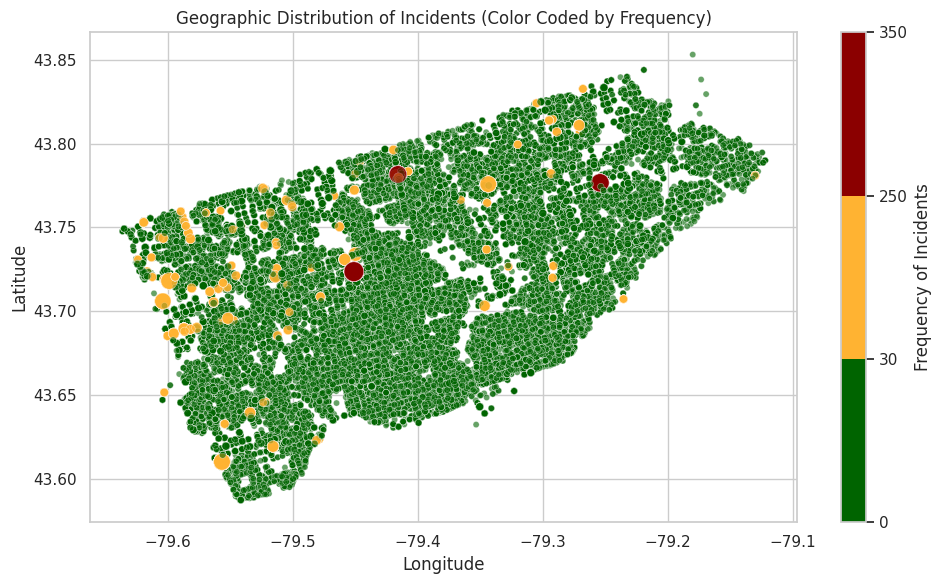

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


===== Top 10 Most Frequent Incident Locations =====

Geo_Location
-79.4513062, 43.7236571    346
-79.2542411, 43.7766363    290
-79.4159903, 43.781633     265
-79.5991709, 43.7180963    237
-79.5569096, 43.6101506    236
-79.3437465, 43.7758819    228
-79.6042074, 43.7060265    226
-79.4501051, 43.733978     150
-79.5141279, 43.7206421    105
-79.587293, 43.6895127     100
Generating Correlation Heatmap...

===== Correlation Matrix =====
                       OCC_YEAR   OCC_DAY   OCC_DOY  OCC_HOUR  LONG_WGS84  \
OCC_YEAR               1.000000  0.000366 -0.041942 -0.050614    0.073160   
OCC_DAY                0.000366  1.000000  0.076077 -0.005412   -0.001582   
OCC_DOY               -0.041942  0.076077  1.000000 -0.001693    0.003060   
OCC_HOUR              -0.050614 -0.005412 -0.001693  1.000000   -0.002338   
LONG_WGS84             0.073160 -0.001582  0.003060 -0.002338    1.000000   
LAT_WGS84              0.037494  0.003682 -0.005110 -0.016461    0.422169   
reporting_delay_ho

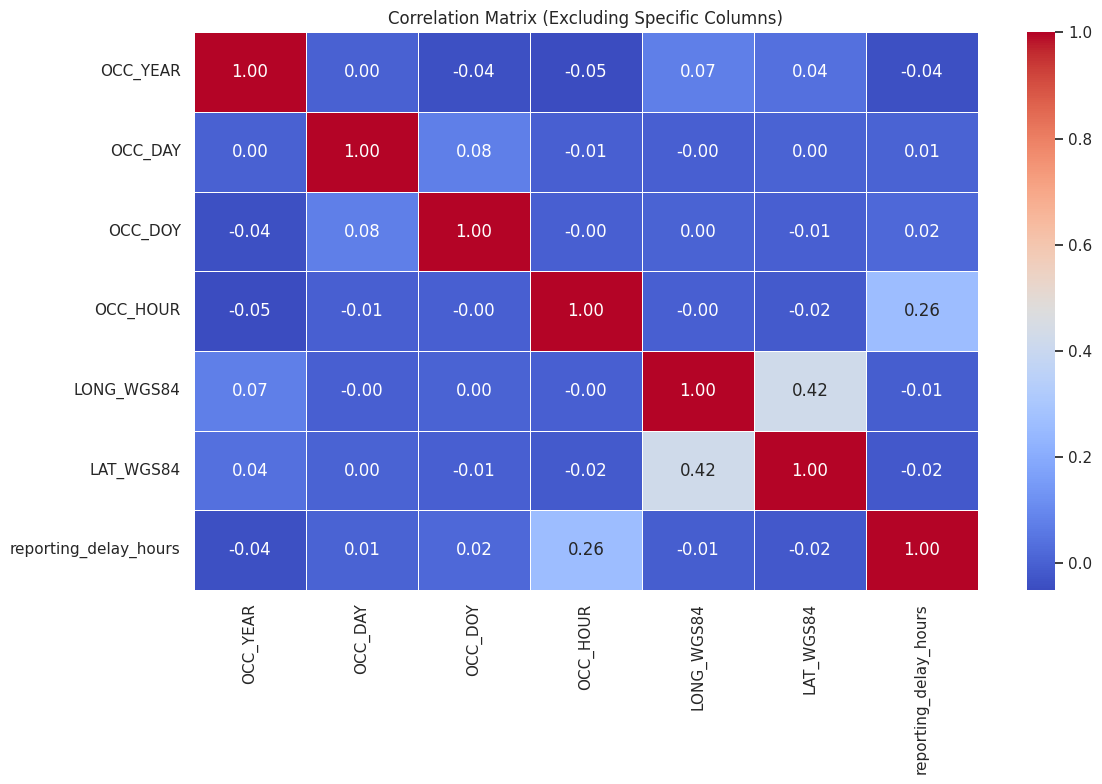

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap
from scipy import stats
from IPython.display import display, HTML
from google.colab import files
import os

                                                                                  # Ignore specific warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

                                                                                  # Read the dataset from CSV (using the URL)
url = "https://raw.githubusercontent.com/mohammadbadi/CrimeAnalytics_Clustering/refs/heads/main/Output_CSV/Final_Data.csv"
original_df = pd.read_csv(url, low_memory=False)

                                                                                  # Create copies for different visualizations
df_box = original_df.copy().drop(columns=['_id', 'EVENT_UNIQUE_ID', 'HOOD_158'])
df_line = original_df.copy()                                                      # For missing values line chart
df_bar = original_df.copy().drop(columns=['_id', 'EVENT_UNIQUE_ID', 'HOOD_158'])
df_cat = df_bar.copy()                                                            # For categorical distribution
df_geo = original_df.copy()                                                       # For geographic scatter
df_corr = original_df.copy()                                                      # For correlation heatmap
                                                                                  # 1) Box Plot of Numerical Features
print("Generating Box Plot for Numerical Features...")
numerical_columns = df_box.select_dtypes(include=['float64', 'int64']).columns
ncols = 4                                                                         # 4 box plots per row
nrows = (len(numerical_columns) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 2.5 * nrows))
axes = axes.flatten()
for i, col in enumerate(numerical_columns):
    sns.boxplot(x=df_box[col], ax=axes[i], color="#8A0000")
    axes[i].set_title(f"Box Plot: {col}")
    axes[i].tick_params(axis='x', rotation=45)
                                                                                  # Remove any unused axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
box_plot_filepath = "EDA_Boxplot_Numerical_Features.png"
plt.savefig(box_plot_filepath)
plt.show()
files.download(box_plot_filepath)
                                                                                  # 2) Line Chart: Percentage of Missing Values per Column
print("Generating Line Chart for Missing Values per Column...")
missing_percent = df_line.isnull().mean() * 100
plt.figure(figsize=(10, 3))
missing_percent.plot(kind='line', color='b', marker='o', linestyle='-', linewidth=2)
plt.axhline(0, color='black', linestyle='--')
plt.title("Percentage of Missing Values per Column", fontsize=16)
plt.xlabel("Columns", fontsize=14)
plt.ylabel("Missing Value (%)", fontsize=12)
plt.xticks(rotation=40)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
missing_values_chart_path = "EDA_Missing_Values.png"
plt.savefig(missing_values_chart_path)
plt.show()
files.download(missing_values_chart_path)
                                                                                  # 3) Bar Plot: Incidents per Year, Month, Day of the Week
print("Generating Bar Plots for Incidents per Year, Month, and Day of the Week...")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
                                                                                  # Ensure proper data types and ordering
df_bar['OCC_YEAR'] = df_bar['OCC_YEAR'].astype(int)
df_bar['OCC_MONTH'] = df_bar['OCC_MONTH'].str[:3]                                 # Use first 3 letters
df_bar['OCC_DOW'] = df_bar['OCC_DOW'].str[:3]                                     # Use first 3 letters
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
dow_order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
df_bar['OCC_MONTH'] = pd.Categorical(df_bar['OCC_MONTH'], categories=month_order, ordered=True)
df_bar['OCC_DOW'] = pd.Categorical(df_bar['OCC_DOW'], categories=dow_order, ordered=True)
sns.countplot(x='OCC_YEAR', data=df_bar, palette='coolwarm', ax=axes[0]).set_title("Incidents Per Year")
sns.countplot(x='OCC_MONTH', data=df_bar, palette='coolwarm', ax=axes[1]).set_title("Incidents Per Month")
sns.countplot(x='OCC_DOW', data=df_bar, palette='coolwarm', ax=axes[2]).set_title("Incidents Per Day of the Week")
for ax in axes:
    ax.tick_params(axis='x', rotation=45)
incidents_path = "EDA_Incidents_Per_Year_Month_DayOfWeek.png"
plt.tight_layout()
plt.savefig(incidents_path)
plt.show()
files.download(incidents_path)
                                                                                  # 4) Bar Plot: Distribution of Categorical Features
                                                                                  # (DIVISION, LOCATION_TYPE, PREMISES_TYPE, NEIGHBOURHOOD_158)
print("Generating Distribution Plots for Categorical Features...")
categorical_columns = ['DIVISION', 'LOCATION_TYPE', 'PREMISES_TYPE', 'NEIGHBOURHOOD_158']
fig, axes = plt.subplots(len(categorical_columns) // 2, 2, figsize=(15, 5 * (len(categorical_columns) // 2)))
axes = axes.flatten()
for idx, col in enumerate(categorical_columns):
    print(f"\n===== {col} Distribution =====\n")
    print(df_cat[col].value_counts().to_string())
    print("\n" + "="*40 + "\n")
    top_categories = df_cat[col].value_counts().nlargest(10)
    sns.countplot(y=df_cat[col], order=top_categories.index, palette="viridis", ax=axes[idx])
    axes[idx].set_title(f"Distribution of {col}")
    labels = [label.get_text()[:15] for label in axes[idx].get_yticklabels()]
    axes[idx].set_yticklabels(labels)
plt.tight_layout()
categorical_dist_path = "EDA_Categorical_Distribution.png"
plt.savefig(categorical_dist_path)
plt.show()
files.download(categorical_dist_path)
                                                                                  # 5) Colour Coded Scatter Plot (Geographic Distribution)
print("Generating Colour Coded Scatter Plot for Geographic Distribution...")
df_geo['Geo_Location'] = df_geo['LONG_WGS84'].round(7).astype(str) + ", " + df_geo['LAT_WGS84'].round(7).astype(str)
location_counts = df_geo['Geo_Location'].value_counts()
df_geo['Location_Frequency'] = df_geo['Geo_Location'].map(location_counts)
boundaries = [0, 30, 250, 350]
colors = ['#006400', '#FFFF00', '#FF6666', '#8B0000']
cmap = LinearSegmentedColormap.from_list("custom_green_yellow_red", colors, N=256)
norm = BoundaryNorm(boundaries, cmap.N)
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(x='LONG_WGS84', y='LAT_WGS84', data=df_geo, hue='Location_Frequency', palette=cmap,
                size='Location_Frequency', sizes=(20, 200), alpha=0.6, legend=None,
                hue_norm=norm, ax=ax)
ax.set_title("Geographic Distribution of Incidents (Color Coded by Frequency)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
fig.colorbar(sm, ax=ax, label="Frequency of Incidents")
plt.tight_layout()
geo_plot_filepath = "Geographic_Scatter_Plot.png"
plt.savefig(geo_plot_filepath, dpi=300, bbox_inches='tight')
plt.show()
files.download(geo_plot_filepath)
print("\n===== Top 10 Most Frequent Incident Locations =====\n")
print(location_counts.head(10).to_string())
print("="*40)

                                                                                  # 6) Correlation Heatmap
print("Generating Correlation Heatmap...")
df_corr_clean = df_corr.drop(columns=['_id', 'EVENT_UNIQUE_ID', 'reporting_delay_days', 'HOOD_158'])
df_corr_clean['OCC_MONTH'] = pd.Categorical(df_corr_clean['OCC_MONTH'], categories=[
    'January', 'February', 'March', 'April', 'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'], ordered=False)
df_corr_clean['OCC_DOW'] = pd.Categorical(df_corr_clean['OCC_DOW'], categories=[
    'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'], ordered=False)
df_numerical = df_corr_clean.select_dtypes(include=[np.number])
correlation_matrix = df_numerical.corr()
print("\n===== Correlation Matrix =====")
print(correlation_matrix)
print("="*40)
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, cbar=True)
plt.title("Correlation Matrix (Excluding Specific Columns)")
plt.tight_layout()
corr_plot_filepath = "Correlation_Heatmap.png"
plt.savefig(corr_plot_filepath, dpi=300, bbox_inches='tight')
plt.show()
files.download(corr_plot_filepath)
